In [1]:
import pandas as pd 
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,accuracy_score
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics  import classification_report

# 1.1

In [4]:

def load_and_preprocess_data(file_path):
    
    df = pd.read_json(file_path)
    
    def denoising_pipeline(text):
        if not isinstance(text, str):
            return ""
       
        text = text.lower()
        text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
        text = re.sub(r'<.*?>', '', text)
        text = re.sub(r'\S+@\S+', '', text)
        text = re.sub(r'[^a-zA-Z\s]', '', text)
        text = re.sub(r'\s+', ' ', text).strip()
        return text

   
    df['cleaned_abstract'] = df['Abstract'].apply(denoising_pipeline)
    df = df[df['cleaned_abstract'].str.len() > 0].reset_index(drop=True)
    
    print(f"Successfully loaded and preprocessed {len(df)} records.")
    return df

df_clean = load_and_preprocess_data("research_abstracts.json")
print(df_clean.head(2))

Successfully loaded and preprocessed 1138 records.
                          DOI  \
0        10.1155/2021/1071145   
1  10.1007/s43546-022-00384-2   

                                            Abstract Label  \
0  Forward-looking forecasting of the inflation r...    ai   
1  Our study examined the disaggregation of infla...    ai   

                                    cleaned_abstract  
0  forwardlooking forecasting of the inflation ra...  
1  our study examined the disaggregation of infla...  


+ On 1.1 i loaded the dataset containing the text articles and performed text cleaning steps like lowercasing,striping stopwords and lemmatization
+ The output  of this is a cleaned tokenized text sequences that is ready to be transformed into numerical vectors

# 1.2

In [5]:
def engineer_features(df, max_features=5000):
   
    text_column = "cleaned_abstract"
    target_column = "Label"
    
    X_text = df[text_column]
    y = df[target_column]
    
   
    vectorizer = TfidfVectorizer(max_features=max_features, stop_words='english')
    X_features = vectorizer.fit_transform(X_text)
    
    print(f"Feature matrix shape: {X_features.shape}")
    return X_features, y, vectorizer


X_test, y_test, vec_test = engineer_features(df_clean)
print("Vocabulary sample:", list(vec_test.vocabulary_.keys())[:5])


Feature matrix shape: (1138, 5000)
Vocabulary sample: ['forwardlooking', 'forecasting', 'inflation', 'rate', 'help']


+ Here in 1.2 i defined texts and target columns where the function extracts the preprocessed text data such as cleaned_abstract as the feature inputs(X_text) and the classification labes as the target outputs(y)
+ And i used TF-IDF Vectorization to convert raw text documents into numerical features so that the machine learning algorithms can process them.
+ The output here is the feature matrix shape which has 1138 rows that indicates that the cleaned dataset contains 1138 research abstracts.And 5000 colums which confirms that the TF-IDF vectorizer have successfully extracted up to 5000 unique,weighted terms for the text corpus
+ The vocabulary samples displays five five representative words that are learned from the research abstracts.

# 1.3

In [7]:
df_clean = load_and_preprocess_data("research_abstracts.json")
X,y,vectorizer=engineer_features( df_clean,max_features=5000)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(" training baseline model")
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)

train_preds = baseline_model.predict(X_train)
test_preds = baseline_model.predict(X_test)

train_acc = accuracy_score(y_train, train_preds)
test_acc = accuracy_score(y_test, test_preds)

print(f"\n[Performance Report]")
print(f"Training Accuracy-Model Learning: {train_acc:.4f}")
print(f"Testing Accuracy-Model Generalization: {test_acc:.4f}")
print("\nDetailed Classification Report (Test Set):")
print(classification_report(y_test, test_preds))

Successfully loaded and preprocessed 1138 records.
Feature matrix shape: (1138, 5000)
 training baseline model

[Performance Report]
Training Accuracy-Model Learning: 0.8890
Testing Accuracy-Model Generalization: 0.8465

Detailed Classification Report (Test Set):
              precision    recall  f1-score   support

          ai       1.00      0.27      0.43        48
   classical       0.84      1.00      0.91       180

    accuracy                           0.85       228
   macro avg       0.92      0.64      0.67       228
weighted avg       0.87      0.85      0.81       228



+ In 1.3 i performed data splitting using train_test_split where it divided the vectorized features (X) and target lables(y) into training and testing sets
+ The output for this question is the Training Accuracy-Model Learning where the model correctly classifies about 88.9% of the training examples and it shows that it has successfully learned patterns from the 80% training subset
+ And the testing Accuracy-model generalization where the model achieves approximately 84.6% accuracy on the unseen test set.
+ For the AI class which supports 48 samples contains precision of 1.00 which shows that the model predicts a document that belongs to  the AI class.The Recall(0.27) where the model only catches 72% of the actual AI documents and the F1-score(0.43) which shows the harmonic mean of the precision and recall for the AI class.
+ For the classical class(support 180 samples) where the precision and recall model excels at identifying the classical abstracts,capturing all of them.
+ For the Macro average the averages metrics equally across classes yeilding the F1-score of 0.67
+ and lastly for the weighted Average: it weighs metrics byt support size and yielding the overall F1-score 0.81 reflecting the strong performance heavily driven by the majority class.

# 2.1 

In [8]:
model={
    "random forest":RandomForestClassifier(random_state=42),
    "SVM":SVC(kernel="linear",random_state=42),
    "multinomial naive bayes":MultinomialNB(),
    "graident boosting":GradientBoostingClassifier(random_state=42)
}

model_performance={}

for name,model in model.items():
    model.fit(X_train,y_train)
    preds=model.predict(X_test)
    acc=accuracy_score(y_test,preds)
    model_performance[name]= {
        "model":model,
        "accuracy":acc
    }
    print(f'{name} -> test accuracy:{acc:.4f}')
    

random forest -> test accuracy:0.9123
SVM -> test accuracy:0.9035
multinomial naive bayes -> test accuracy:0.8158
graident boosting -> test accuracy:0.9254


# 2.2

In [9]:
enhanced_LR = LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42)
enhanced_LR.fit(X_train,y_train)
enhanced_RF=RandomForestClassifier(class_weight="balanced",random_state=42)
enhanced_RF.fit(X_train,y_train)

print("The enhanced logistic regression balanced report:")
LR_preds=enhanced_LR.predict(X_test)
print(classification_report(y_test,LR_preds))

print("The Enhanced random forest balanced report:")
RF_preds=enhanced_RF.predict(X_test)
print( classification_report(y_test,RF_preds))




The enhanced logistic regression balanced report:
              precision    recall  f1-score   support

          ai       0.69      0.75      0.72        48
   classical       0.93      0.91      0.92       180

    accuracy                           0.88       228
   macro avg       0.81      0.83      0.82       228
weighted avg       0.88      0.88      0.88       228

The Enhanced random forest balanced report:
              precision    recall  f1-score   support

          ai       0.93      0.58      0.72        48
   classical       0.90      0.99      0.94       180

    accuracy                           0.90       228
   macro avg       0.92      0.79      0.83       228
weighted avg       0.91      0.90      0.89       228



# 2.3

In [ ]:
!pip install gradio

In [16]:
import gradio as gr
import re

def classify_abstract(abstract_text):
    if not abstract_text.strip():
        return "enter the valid research abstract"

    text=abstract_text.lower()
    text=re.sub(r'http\S+|www\S+|https\S+','',text,flags=re.MULTILINE)
    text=re.sub(r'<.*?>','',text)
    text=re.sub(r'\S+@\S+','',text)
    text=re.sub(r'[^a-zA-Z\s]','',text)
    cleaned=re.sub(r'\s+','',text).strip()

    X_input=vectorizer.transform([cleaned])
    prediction=enhanced_LR.predict(X_input)[0]
    return f'the abstract is classified as :{prediction}'
demo=gr.Interface(
    fn=classify_abstract,
    inputs=gr.Textbox(
        lines=4,
        label='enter the research abstract:',
        placeholder='paste your research abstract here...'
    ),
    outputs=gr.Textbox(label='Prediction'),
    title='Researchly research abstract classifier',
    description='This app classifies the research abstracts as either ai-related or classical research.'
)

demo.launch(inline=True)
    

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


+ For question 2 the vectorization was applied such as vectorizer_corpus to convert the text corpus into a document term matrix,each row represents the document where each column represents a unique vocabulary and the cells values represent word frequencies



# 3.1

In [19]:
import os
import json
import pandas as pd

def load_corpus(zip_path='research_corpus.zip',extract_dir="extracted_corpus"):
    if os.path.exists(zip_path) and not os.path.exists(extract_dir):
        import zipfile
        with zipfile.ZipFile(zip_path,'r') as zip_ref:
            zip_ref.extractall(extract_dir)
    data_records=[]
    json_path = os.path.join(extract_dir,'research_abstracts.json')
    if os.path.exists(json_path):
        with open(json_path,'r',encoding='utf-8') as r:
            raw_data=json.load(r)
            df=pd.DataFrame(raw_data)

    else:
        for root,dirs,files in os.walk(extract_dir):
            for file in files:
                if file.endswith('.json'):
                    with open(os.path.join(root,file),'r',encoding='utf-8') as r:
                        content=json.load(r)
                        data_records.append(content)
                elif file.endswith('.txt'):
                    with open(os.path.join(root,file),'r',encoding='utf-8') as r:
                        text=r.read()
                        data_records.append({'filename':file,'content':text})
    df=pd.DataFrame(data_records)
    print(f'successfully loaded {len(df)} articles into the DataFrame')
    print('The columns available:',df.columns.tolist())
    return df

df_corpus=load_corpus()
display(df_corpus.head(3))
        

successfully loaded 5 articles into the DataFrame
The columns available: ['filename', 'content']


,filename,content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...


# 3.2

In [28]:
import re

def advanced_denoising(text):
    if not isinstance(text,str):
        return ""
    text=text.lower()
    text=re.sub(r'http\S+|www\S+|https\S+','',text,flags=re.MULTILINE)
    text=re.sub(r'<.*?>','',text)
    text=re.sub(r'\S+@\S+','',text)
    text=re.sub(r'[^a-zA-Z\s]','',text)
    text=re.sub(r'\s+',' ',text).strip()
    return text

text_col= 'Abstract' if 'Abstract' in df_corpus.columns else 'content'
df_corpus['cleaned_content']=df_corpus[text_col].apply(advanced_denoising)

df_corpus=df_corpus[df_corpus['cleaned_content'].str.len() > 0].reset_index(drop=True)
print(f'The preprocessed {len(df_corpus)} valid articles')
    

The preprocessed 5 valid articles


# 3.3

--- Original Title ---
research_1.txt
[ The extractive summary of article 1]:
Again, however,
a strong relativism or strong constructivism runs into problems;
for example, it is not a matter of opinion (or individual reality)
that one should or can drive on the left-hand side of the road in
Great Britain—if one chooses to drive on the right side, he or she
will likely have a head-on collision, at some point, and end up in
the hospital intensive care unit, or worse (this is a case where subjective and objective realities directly meet and clash). Again, however,
a strong relativism or strong constructivism runs into problems;
for example, it is not a matter of opinion (or individual reality)
that one should or can drive on the left-hand side of the road in
Great Britain—if one chooses to drive on the right side, he or she
will likely have a head-on collision, at some point, and end up in
the hospital intensive care unit, or worse (this is a case where subjective and objective realities 

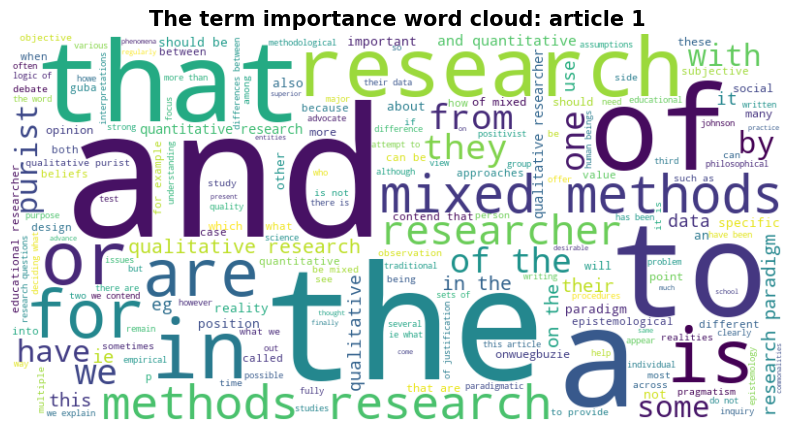

In [29]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

first_article=df_corpus.loc[0,'cleaned_content']
print('--- Original Title ---')
print(df_corpus.loc[0].get('DOI',df_corpus.loc[0].get('filename','Article 1')))

sentences =[s.strip() for s in df_corpus.loc[0][text_col].split('.') if  len(s.strip()) > 10]
if len(sentences) > 3:
    vectorizer =TfidfVectorizer(stop_words='english')
    X_sent=vectorizer.fit_transform(sentences)
    sent_scores=np.array(X_sent.sum(axis=1)).flatten()
    ranked_indices=sent_scores.argsort()[::-1]

    summary_sentences=[sentences[i] for i in sorted(ranked_indices[:2])]
    summary = ". ".join(summary_sentences) + "."
else:
    summary=first_article
print('[ The extractive summary of article 1]:')
print(summary)

wordcloud = WordCloud(width=800,height=400,background_color='white',colormap='viridis',stopwords='english').generate(first_article)
plt.figure(figsize=(10,7))
plt.imshow(wordcloud,interpolation='bilinear')
plt.axis('off')
plt.title(f'The term importance word cloud: article 1',fontsize=15,fontweight='bold')
plt.show()

 theme / topic 1 :alpha , mixed , methods , quantitative , instrument , researchers
 theme / topic 2 :triangulation , development , design , evaluation , researchers , type
 theme / topic 3 :researcher , researchers , experience , personal , participants , reactions


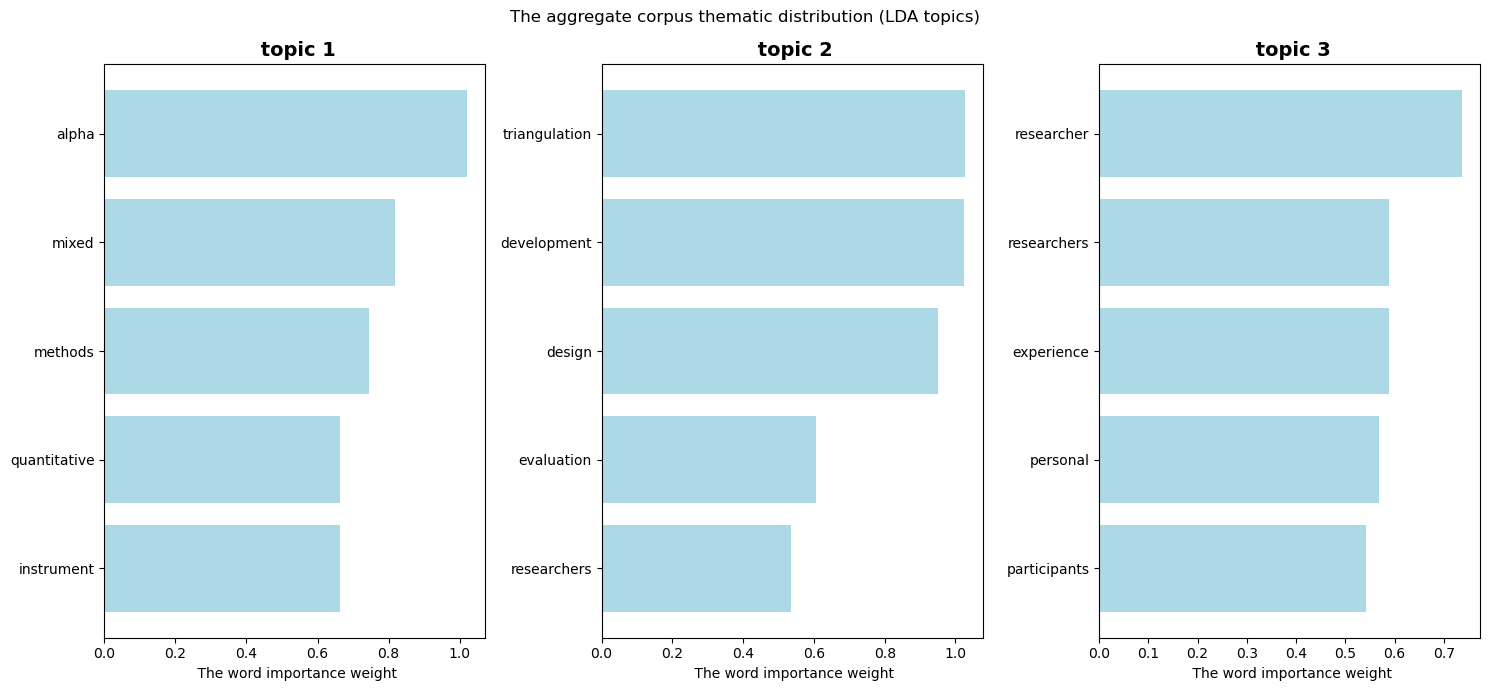

In [34]:
from sklearn.decomposition import LatentDirichletAllocation

vectorizer_corpus = TfidfVectorizer(max_features=2000,stop_words='english',max_df=0.85,min_df=2)
doc_term_matrix=vectorizer_corpus.fit_transform(df_corpus['cleaned_content'])

n_topics=3
lda_model=LatentDirichletAllocation(n_components=n_topics,random_state=42)
lda_model.fit( doc_term_matrix)
feature_names=vectorizer_corpus.get_feature_names_out()
n_top_words=6

topic_summaries={}
for topic_idx,topic in enumerate(lda_model.components_):
    top_features_ind=topic.argsort()[::-1][:n_top_words]
    top_features=[feature_names[i] for i in top_features_ind]
    topic_summaries[f'topic {topic_idx+1} ']=top_features
    print(f' theme / topic {topic_idx+1} :{ ' , '.join(top_features)}')

fig,axes = plt.subplots(1,n_topics,figsize=(15,7),sharey=False)
for topic_idx, topic in enumerate(lda_model.components_):
    top_features_ind=topic.argsort()[::-1][:5]
    top_features=[feature_names[i] for i in top_features_ind]
    weights = [topic[i] for i in top_features_ind]

    ax = axes[topic_idx] if n_topics > 1 else axes
    ax.barh(top_features[::-1],weights[::-1],color='lightblue')
    ax.set_title(f' topic {topic_idx + 1}',fontsize=14,fontweight='bold')
    ax.set_xlabel(' The word importance weight')

plt.suptitle('The aggregate corpus thematic distribution (LDA topics)')
plt.tight_layout()
plt.show()
    

+ for question 3 the LDA model on the document-term matrix and LDA is the generative probailistic  model that assumes each document is a mixture of various topics  and each topic is a mixture of words.
+ the output of question 3 is the trained topic distributions for the documents which is doc_topic_distr and term weights for topics which is lda_model.components that allows the algorithm to categorize and cluster the core themes of the corpus.

# 4.1

 theme / topic 1 :alpha , mixed , methods , quantitative , instrument , researchers
 theme / topic 2 :triangulation , development , design , evaluation , researchers , type
 theme / topic 3 :researcher , researchers , experience , personal , participants , reactions


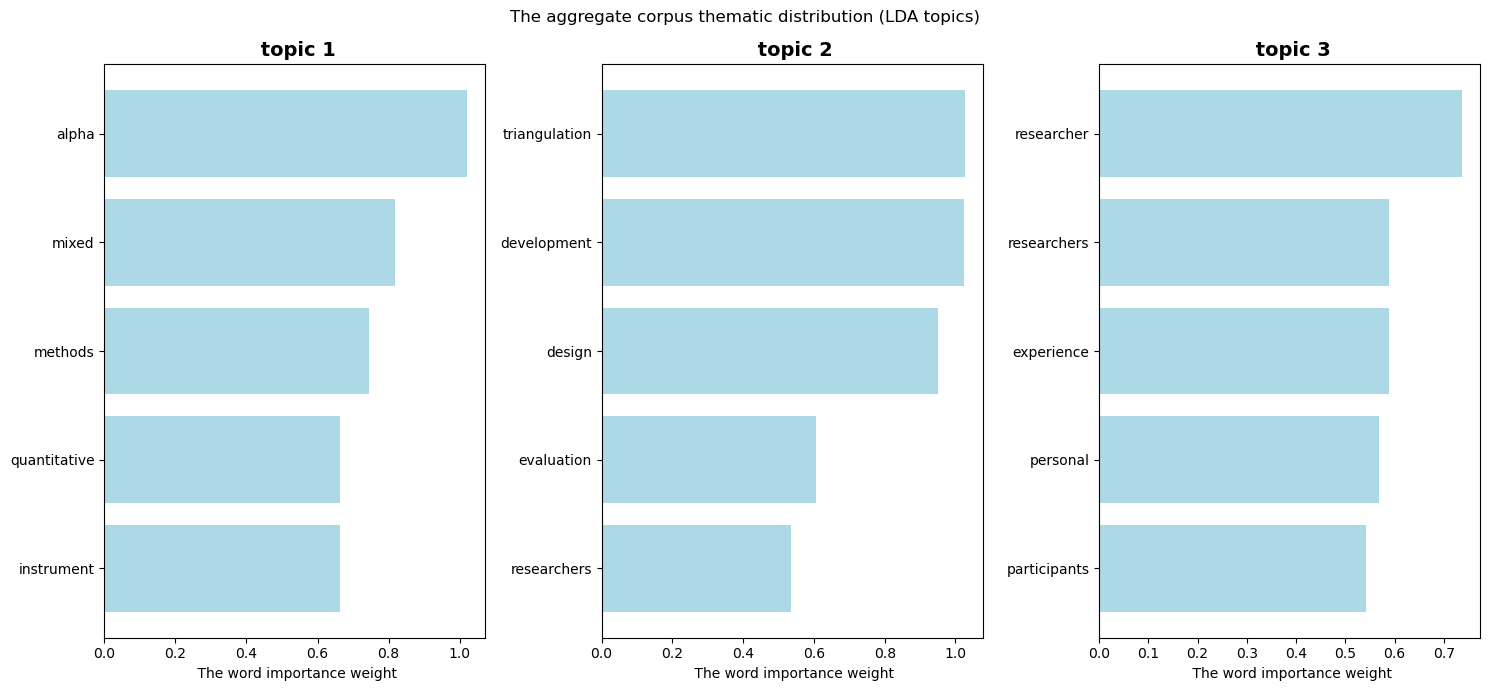

In [35]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

vectorizer_corpus = TfidfVectorizer(max_features=2000,stop_words='english',max_df=0.85,min_df=2)
doc_term_matrix=vectorizer_corpus.fit_transform(df_corpus['cleaned_content'])
n_topics=3
lda_model=LatentDirichletAllocation(n_components=n_topics,random_state=42)
lda_model.fit( doc_term_matrix)
feature_names=vectorizer_corpus.get_feature_names_out()
n_top_words=6

for topic_idx,topic in enumerate(lda_model.components_):
    top_features_ind=topic.argsort()[::-1][:n_top_words]
    top_features=[feature_names[i] for i in top_features_ind]
    print(f' theme / topic {topic_idx+1} :{ ' , '.join(top_features)}')

fig,axes = plt.subplots(1,n_topics,figsize=(15,7),sharey=False)
for topic_idx, topic in enumerate(lda_model.components_):
    top_features_ind=topic.argsort()[::-1][:5]
    top_features=[feature_names[i] for i in top_features_ind]
    weights = [topic[i] for i in top_features_ind]

    ax = axes[topic_idx] if n_topics > 1 else axes
    ax.barh(top_features[::-1],weights[::-1],color='lightblue')
    ax.set_title(f' topic {topic_idx + 1}',fontsize=14,fontweight='bold')
    ax.set_xlabel(' The word importance weight')




plt.suptitle('The aggregate corpus thematic distribution (LDA topics)')
plt.tight_layout()
plt.show()  

# 4.2

In [41]:
import pyLDAvis
import numpy as np

pyLDAvis.enable_notebook()
doc_topic_distr=lda_model.transform(doc_term_matrix)
topic_term_distr=lda_model.components_ / lda_model.components_.sum(axis=1)[:,np.newaxis]
doc_lengths=doc_term_matrix.sum(axis=1).A1
vocab =vectorizer_corpus.get_feature_names_out()
term_frequency = doc_term_matrix.sum(axis=0).A1
panel=pyLDAvis.prepare(
    topic_term_dists=topic_term_distr,
    doc_topic_dists=doc_topic_distr,
    doc_lengths=doc_lengths,
    vocab=vocab,
    term_frequency=term_frequency,
    mds='tsne'
    )
pyLDAvis.display(panel)

+ the output of  4.2 is the following:
+ for the left plane it projects the tops onto the 2D plane using t-SNE.The numbered circles which are topic 1 and topic 2 represents the distinct themes and the distance between shows how different they are.
+ The right plane displays the key vocubulary driving the selected topic,for example topic 1 highlights the qualitative and research oritented terms such as alpha and experience ,which indicates the focus is on the study design,feedback and methodologies.